# Module 7 Lab 1: Train, Test, Tell the Truth

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.datasets import load_iris
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree

print("scikit-learn version:", sklearn.__version__)
print("All libraries imported successfully.")

scikit-learn version: 1.9.1
All libraries imported successfully.


## Load tips.csv and frame the problem


In [2]:
df_tips = pd.read_csv("tips.csv")

X_tips = df_tips[["total_bill"]]
y_tips = df_tips["tip"]

X_train_tips, X_test_tips, y_train_tips, y_test_tips = train_test_split(
    X_tips, y_tips, test_size=0.3, random_state=42
)

print("Total observations:", len(df_tips))
print("Training observations:", len(X_train_tips))
print("Test observations:", len(X_test_tips))

print("\nFirst five rows:")
print(df_tips.head())

Total observations: 244
Training observations: 170
Test observations: 74

First five rows:
   total_bill   tip     sex smoker  day    time  size
0       16.99  1.01  Female     No  Sun  Dinner     2
1       10.34  1.66    Male     No  Sun  Dinner     3
2       21.01  3.50    Male     No  Sun  Dinner     3
3       23.68  3.31    Male     No  Sun  Dinner     2
4       24.59  3.61  Female     No  Sun  Dinner     4


##  Why Hold Out 30%?
We reserve 30% of the data for testing to evaluate how accurately the model predicts new observations. Using data that was not included in training provides a more reliable measure of performance and helps us identify possible overfitting.

## Fit the regression and read the slope


In [3]:
model_tips = LinearRegression()
model_tips.fit(X_train_tips, y_train_tips)

slope_tips = model_tips.coef_[0]
intercept_tips = model_tips.intercept_

print("Slope:", round(slope_tips, 4))
print("Intercept:", round(intercept_tips, 4))

Slope: 0.1089
Intercept: 0.877


### The model predicts each extra dollar of the total bill adds about 0.11 dollars to the predicted tip.

##  Draw the fitted line


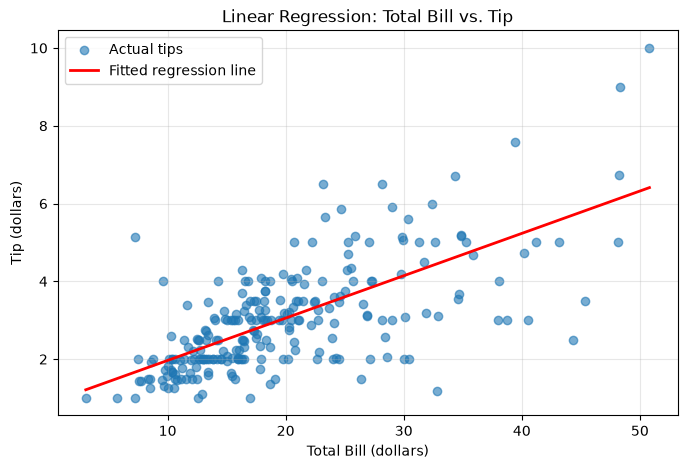

In [4]:
plt.figure(figsize=(8, 5))

plt.scatter(X_tips["total_bill"], y_tips, alpha=0.6, label="Actual tips")

X_line_tips = X_tips.sort_values("total_bill")
y_line_tips = model_tips.predict(X_line_tips)

plt.plot(X_line_tips["total_bill"], y_line_tips,
         color="red", linewidth=2, label="Fitted regression line")

plt.title("Linear Regression: Total Bill vs. Tip")
plt.xlabel("Total Bill (dollars)")
plt.ylabel("Tip (dollars)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

##  Load iris and split it


In [5]:
iris = load_iris(as_frame=True)

X_iris = iris.data
y_iris = iris.target

X_train_iris, X_test_iris, y_train_iris, y_test_iris = train_test_split(
    X_iris, y_iris, test_size=0.3, random_state=42
)

print("Total observations:", len(X_iris))
print("Training observations:", len(X_train_iris))
print("Test observations:", len(X_test_iris))

print("\nFirst five rows:")
print(X_iris.head())

print("\nFlower species:", iris.target_names)

Total observations: 150
Training observations: 105
Test observations: 45

First five rows:
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0                5.1               3.5                1.4               0.2
1                4.9               3.0                1.4               0.2
2                4.7               3.2                1.3               0.2
3                4.6               3.1                1.5               0.2
4                5.0               3.6                1.4               0.2

Flower species: ['setosa' 'versicolor' 'virginica']


## Fit and score kNN


In [6]:
knn_iris = KNeighborsClassifier(n_neighbors=5)
knn_iris.fit(X_train_iris, y_train_iris)

knn_test_accuracy = knn_iris.score(X_test_iris, y_test_iris)

print("kNN test accuracy:", round(knn_test_accuracy, 4))

kNN test accuracy: 1.0


## Fit, score, and read a shallow tree

Decision tree test accuracy: 1.0


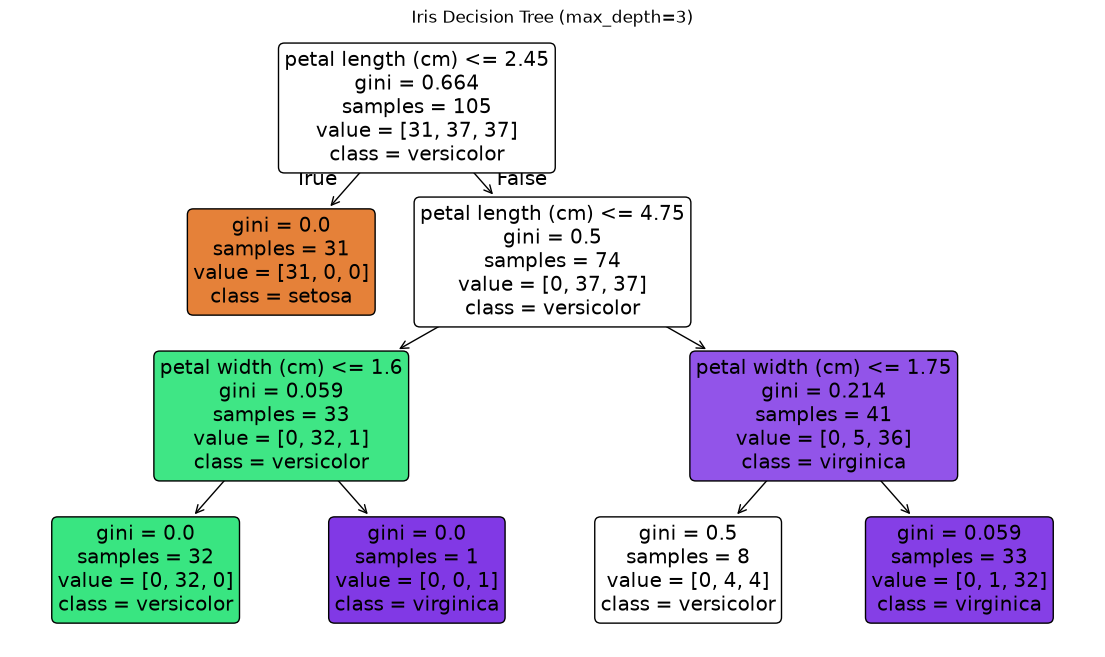

In [7]:
tree_iris = DecisionTreeClassifier(max_depth=3, random_state=42)
tree_iris.fit(X_train_iris, y_train_iris)

tree_test_accuracy = tree_iris.score(X_test_iris, y_test_iris)

print("Decision tree test accuracy:", round(tree_test_accuracy, 4))

plt.figure(figsize=(14, 8))
plot_tree(
    tree_iris,
    feature_names=X_iris.columns,
    class_names=iris.target_names,
    filled=True,
    rounded=True
)
plt.title("Iris Decision Tree (max_depth=3)")
plt.show()

### The root split checks whether the flower’s petal length is 2.45 cm or less, separating setosa from the other two species.

## The overfitting probe

In [8]:
tree_unlimited_iris = DecisionTreeClassifier(random_state=42)
tree_unlimited_iris.fit(X_train_iris, y_train_iris)

tree_scores = pd.DataFrame({
    "Model": ["Shallow tree (max_depth=3)", "Unlimited tree"],
    "Train accuracy": [
        tree_iris.score(X_train_iris, y_train_iris),
        tree_unlimited_iris.score(X_train_iris, y_train_iris)
    ],
    "Test accuracy": [
        tree_iris.score(X_test_iris, y_test_iris),
        tree_unlimited_iris.score(X_test_iris, y_test_iris)
    ]
})

print(tree_scores.to_string(index=False))

                     Model  Train accuracy  Test accuracy
Shallow tree (max_depth=3)        0.952381            1.0
            Unlimited tree        1.000000            1.0


### The unlimited tree reaches 100% training accuracy but does not outperform the shallow tree on the test data, as both achieve 100% test accuracy.


## Predict one new flower


In [9]:
new_flower = pd.DataFrame(
    [[5.8, 2.8, 4.5, 1.3]],
    columns=X_iris.columns
)

predicted_class = tree_iris.predict(new_flower)[0]
predicted_species = iris.target_names[predicted_class]

print("New flower measurements:")
print(new_flower.to_string(index=False))
print("\nPredicted species:", predicted_species)

New flower measurements:
 sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
               5.8               2.8                4.5               1.3

Predicted species: versicolor


### The model report 
We trained classification models to predict Iris flower species using sepal and petal measurements. The kNN model and both decision trees achieved 100% accuracy on the test data. I would choose the shallow decision tree with max_depth=3 because it is simpler and gives the same test accuracy as the unlimited tree. The model predicted that our new flower belongs to the versicolor species. A perfect test score does not guarantee that the model will work equally well on new data. For example, it might incorrectly classify flowers with unusual measurements. If this model were used to make predictions about people,  and the training data did not represent all groups equally, the model could learn biases and make unfair predictions.